### Time Series Analysis of Network Utilization for Distributed Scientific Workflows
#### Yingxin Deng
#### 2026/10/21

## Causal trend features for next-day hit-size forecasting

This notebook tests whether trend summaries computed from historical `hit_size` improve one-day-ahead Structured TCN forecasts. All trend features are causal: a feature for day *t* uses information from day *t* and earlier only, while the model predicts day *t+1*.

The output structure and loss remain unchanged: the model forecasts access and hit ratio, reconstructs hit and miss, and exactly enforces `access = hit + miss`.

### Experimental design

All models use the post-change-point regime (2022-07-01 to 2024-03-31) with a chronological 70%/15%/15% train-validation-test split. The primary selection metric is validation `hit_size` RMSE; peak/spike error, bias, precision, and recall are diagnostic metrics.

Three fixed comparisons are used:

1. **14-day base reference:** 6 original XCache variables.
2. **28-day base control:** the same 6 variables, with more raw history.
3. **28-day trend model:** 6 original variables plus all 12 `hit_size` trend features.

The 28-day control is essential: it separates the value of longer history from the value of hand-crafted trend features.

In [17]:
from pathlib import Path
import copy
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
FEATURE_NAMES = ['access_count', 'access_size', 'hit_count', 'hit_size', 'miss_count', 'miss_size']
PRIMARY_VARIABLE = 'hit_size'
PRIMARY_INDEX = FEATURE_NAMES.index(PRIMARY_VARIABLE)
CHANNELS = (64, 64, 64, 64, 64)
KERNEL_SIZE, DROPOUT = 3, 0.1
MAX_EPOCHS, PATIENCE, BATCH_SIZE, LEARNING_RATE = 60, 10, 32, 1e-3
PEAK_QUANTILE, SPIKE_QUANTILE = 0.90, 0.90
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

data_dirs = [Path('../xcache-ts-df'), Path('../xcache-ts/pickled_data/df'), Path('xcache-ts-df'), Path('xcache-ts/pickled_data/df')]
data_file = next((directory / 'socal-2006-2403-daily-ml' for directory in data_dirs if (directory / 'socal-2006-2403-daily-ml').is_file()), None)
if data_file is None:
    raise FileNotFoundError('Cannot find the SoCal daily data file.')

df = pd.read_pickle(data_file).loc['2020-05-31':'2024-03-31', FEATURE_NAMES].copy()
df[['access_size', 'hit_size', 'miss_size']] /= 1000 ** 4
assert df.index.equals(pd.date_range('2020-05-31', '2024-03-31', freq='D'))
np.testing.assert_allclose(df['access_count'], df['hit_count'] + df['miss_count'])
np.testing.assert_allclose(df['access_size'], df['hit_size'] + df['miss_size'])
raw_values = df.to_numpy(dtype=np.float32)
date_to_position = pd.Series(np.arange(len(df)), index=df.index)

def chronological_split(start, end):
    dates = pd.date_range(start, end, freq='D')
    n_train, n_validation = int(0.70 * len(dates)), int(0.15 * len(dates))
    return {
        'train_start': dates[0], 'train_end': dates[n_train - 1],
        'validation_start': dates[n_train], 'validation_end': dates[n_train + n_validation - 1],
        'test_start': dates[n_train + n_validation], 'test_end': dates[-1],
    }

split = chronological_split('2022-07-01', '2024-03-31')
split_table = pd.DataFrame([
    {'subset': subset.title(), 'first target': split[f'{subset}_start'].date(), 'last target': split[f'{subset}_end'].date(), 'days': len(pd.date_range(split[f'{subset}_start'], split[f'{subset}_end']))}
    for subset in ['train', 'validation', 'test']
])
display(split_table)
print('Device:', device)

,subset,first target,last target,days
0,Train,2022-07-01,2023-09-21,448
1,Validation,2023-09-22,2023-12-26,96
2,Test,2023-12-27,2024-03-31,96


Device: cpu


### 1. Build the 12 causal trend features

The features are constructed from `hit_size` only. MA levels represent traffic level; relative MA gaps represent short-versus-long trend; EMA gaps emphasize recent momentum; slopes represent recent direction and rate of change. No feature uses a future day.

The full trend model has **18 input channels**: six original variables plus 12 trend features.

In [18]:
def rolling_slope(series, window):
    x = np.arange(window, dtype=float)
    x_centered = x - x.mean()
    denominator = np.sum(x_centered ** 2)
    return series.rolling(window, min_periods=window).apply(
        lambda values: np.sum(x_centered * (values - values.mean())) / denominator, raw=True
    )

def build_trend_features(hit_size):
    trend = pd.DataFrame(index=hit_size.index)
    for window in [7, 14, 21, 28]:
        trend[f'ma_{window}'] = hit_size.rolling(window, min_periods=window).mean()
    for short_window, long_window in [(7, 14), (7, 21), (7, 28), (14, 28)]:
        trend[f'ma_gap_{short_window}_{long_window}'] = (
            trend[f'ma_{short_window}'] - trend[f'ma_{long_window}']
        ) / (trend[f'ma_{long_window}'] + 1e-6)
    ema = {window: hit_size.ewm(span=window, adjust=False).mean() for window in [7, 14, 28]}
    trend['ema_gap_7_14'] = ema[7] - ema[14]
    trend['ema_gap_7_28'] = ema[7] - ema[28]
    trend['slope_3'] = rolling_slope(hit_size, 3)
    trend['slope_7'] = rolling_slope(hit_size, 7)
    return trend

trend_df = build_trend_features(df['hit_size'])
TREND_NAMES = trend_df.columns.tolist()
assert len(TREND_NAMES) == 12
display(pd.DataFrame({'trend feature': TREND_NAMES, 'latest value': trend_df.iloc[-1].to_numpy()}))
display(pd.concat([df[['hit_size']], trend_df], axis=1).tail())

,trend feature,latest value
0,ma_7,99.555043
1,ma_14,83.629474
2,ma_21,75.819950
3,ma_28,64.456758
4,ma_gap_7_14,0.190430
5,ma_gap_7_21,0.313045
6,ma_gap_7_28,0.544525
7,ma_gap_14_28,0.297451
8,ema_gap_7_14,-1.671162
9,ema_gap_7_28,11.491088


,hit_size,ma_7,ma_14,ma_21,ma_28,ma_gap_7_14,ma_gap_7_21,ma_gap_7_28,ma_gap_14_28,ema_gap_7_14,ema_gap_7_28,slope_3,slope_7
data_start_time_datetime,,,,,,,,,,,,,
2024-03-27,46.915437,100.236723,85.491427,66.194150,53.670976,0.172477,0.514284,0.867615,0.592880,18.651254,41.283448,-45.476257,17.614444
2024-03-28,74.928472,102.202442,90.328238,68.451572,56.346993,0.131456,0.493062,0.813805,0.603071,12.370206,32.548740,-67.585773,9.321662
2024-03-29,136.434591,120.558579,96.092375,73.594283,61.219657,0.254611,0.638151,0.969279,0.569633,15.050899,37.023048,44.759577,-0.476438
2024-03-30,68.594539,129.469043,85.757237,76.506229,63.669462,0.509716,0.692268,1.033456,0.346913,8.376979,27.227632,-3.166967,-22.377912
2024-03-31,22.044297,99.555043,83.629474,75.819950,64.456758,0.190430,0.313045,0.544525,0.297451,-1.671162,11.491088,-57.195147,-19.320099


### 2. Define the Structured TCN

The only architectural difference between experiments is the number of input channels. The five residual blocks, 64 channels per block, kernel size, dilation schedule, loss, and structured output remain fixed.

In [19]:
class Chomp1d(nn.Module):
    def __init__(self, size):
        super().__init__()
        self.size = size
    def forward(self, x):
        return x[:, :, :-self.size].contiguous() if self.size else x

class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dilation):
        super().__init__()
        padding = (KERNEL_SIZE - 1) * dilation
        self.net = nn.Sequential(
            nn.Conv1d(in_channels, out_channels, KERNEL_SIZE, padding=padding, dilation=dilation),
            Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Conv1d(out_channels, out_channels, KERNEL_SIZE, padding=padding, dilation=dilation),
            Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT),
        )
        self.residual = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()
    def forward(self, x):
        return torch.relu(self.net(x) + self.residual(x))

class StructuredTCN(nn.Module):
    def __init__(self, input_channels):
        super().__init__()
        blocks, in_channels = [], input_channels
        for level, out_channels in enumerate(CHANNELS):
            blocks.append(TemporalBlock(in_channels, out_channels, 2 ** level))
            in_channels = out_channels
        self.tcn = nn.Sequential(*blocks)
        self.output = nn.Linear(CHANNELS[-1], 4)
    def forward(self, x):
        output = self.output(self.tcn(x)[:, :, -1])
        return torch.cat([output[:, :2], torch.sigmoid(output[:, 2:])], dim=1)

def make_loader(x, y, shuffle=False):
    return DataLoader(
        TensorDataset(torch.tensor(x.transpose(0, 2, 1), dtype=torch.float32), torch.tensor(y, dtype=torch.float32)),
        batch_size=BATCH_SIZE, shuffle=shuffle
    )

def structured_loss(prediction, target):
    return nn.functional.mse_loss(prediction[:, :2], target[:, :2]) + 5 * nn.functional.mse_loss(prediction[:, 2:], target[:, 2:])

def event_metrics(actual_event, predicted_event):
    true_positive = int(np.sum(actual_event & predicted_event))
    precision = true_positive / max(int(predicted_event.sum()), 1)
    recall = true_positive / max(int(actual_event.sum()), 1)
    return precision, recall

### 3. Train the three fixed comparisons

This cell trains the 14-day reference, 28-day base control, and 28-day trend-feature model. Model selection uses validation `hit_size` RMSE. The test metrics are saved for later inspection; do not choose a model using the test rows.

In [20]:
EXPERIMENTS = [
    {'model': '14-day base reference', 'lookback': 14, 'use_trends': False},
    {'model': '28-day base control', 'lookback': 28, 'use_trends': False},
    {'model': '28-day base + all trend features', 'lookback': 28, 'use_trends': True},
]

def fit_and_evaluate(config):
    lookback, use_trends = config['lookback'], config['use_trends']
    train_positions = date_to_position.loc[split['train_start']:split['train_end']].to_numpy()
    validation_positions = date_to_position.loc[split['validation_start']:split['validation_end']].to_numpy()
    test_positions = date_to_position.loc[split['test_start']:split['test_end']].to_numpy()
    train_positions = train_positions[train_positions >= lookback]
    validation_positions = validation_positions[validation_positions >= lookback]
    test_positions = test_positions[test_positions >= lookback]
    train_raw_positions = date_to_position.loc[split['train_start']:split['train_end']].to_numpy()

    # Base inputs are the six observed XCache variables. Trend features are causal summaries of hit_size.
    base_inputs = np.log1p(raw_values).astype(np.float32)
    all_inputs = np.column_stack([base_inputs, trend_df.to_numpy(dtype=np.float32)]) if use_trends else base_inputs
    input_scaler = StandardScaler().fit(all_inputs[train_raw_positions])
    inputs = input_scaler.transform(all_inputs).astype(np.float32)

    count_ratio = np.divide(raw_values[:, 2], raw_values[:, 0], out=np.zeros(len(df)), where=raw_values[:, 0] > 0)
    size_ratio = np.divide(raw_values[:, 3], raw_values[:, 1], out=np.zeros(len(df)), where=raw_values[:, 1] > 0)
    log_access = np.column_stack([np.log1p(raw_values[:, 0]), np.log1p(raw_values[:, 1])]).astype(np.float32)
    access_scaler = StandardScaler().fit(log_access[train_raw_positions])
    labels_all = np.column_stack([access_scaler.transform(log_access), count_ratio, size_ratio]).astype(np.float32)

    def make_sequences(target_positions):
        return np.asarray([inputs[position - lookback:position] for position in target_positions], dtype=np.float32)

    x_train, y_train = make_sequences(train_positions), labels_all[train_positions]
    x_validation, y_validation = make_sequences(validation_positions), labels_all[validation_positions]
    x_test = make_sequences(test_positions)

    def decode(model, x):
        model.eval()
        outputs = []
        with torch.no_grad():
            for start in range(0, len(x), BATCH_SIZE):
                batch = torch.tensor(x[start:start + BATCH_SIZE].transpose(0, 2, 1), dtype=torch.float32, device=device)
                # Use tolist() rather than Tensor.numpy(): this kernel's PyTorch build cannot access NumPy directly.
                outputs.extend(model(batch).cpu().tolist())
        output = np.asarray(outputs, dtype=np.float64)
        access = np.maximum(np.expm1(access_scaler.inverse_transform(output[:, :2])), 0)
        ratio = np.clip(output[:, 2:], 0, 1)
        return np.column_stack([
            access[:, 0], access[:, 1],
            access[:, 0] * ratio[:, 0], access[:, 1] * ratio[:, 1],
            access[:, 0] * (1 - ratio[:, 0]), access[:, 1] * (1 - ratio[:, 1]),
        ])

    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    model = StructuredTCN(input_channels=inputs.shape[1]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    train_loader = make_loader(x_train, y_train, shuffle=True)
    validation_actual = raw_values[validation_positions]
    best_rmse, best_state, best_epoch, stale = float('inf'), None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for xb, yb in train_loader:
            optimizer.zero_grad()
            loss = structured_loss(model(xb.to(device)), yb.to(device))
            loss.backward()
            optimizer.step()
        validation_prediction = decode(model, x_validation)
        validation_rmse = float(np.sqrt(np.mean((validation_prediction[:, PRIMARY_INDEX] - validation_actual[:, PRIMARY_INDEX]) ** 2)))
        if validation_rmse < best_rmse:
            best_rmse, best_state, best_epoch, stale = validation_rmse, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            stale += 1
        if stale >= PATIENCE:
            break
    model.load_state_dict(best_state)

    validation_prediction = decode(model, x_validation)
    test_prediction = decode(model, x_test)
    test_actual, previous_actual = raw_values[test_positions], raw_values[test_positions - 1]
    train_actual, train_previous = raw_values[train_raw_positions], raw_values[train_raw_positions - 1]
    result = {
        **config, 'input_channels': inputs.shape[1], 'best_epoch': best_epoch,
        'validation_hit_size_rmse': best_rmse,
        'validation_access_size_rmse': float(np.sqrt(np.mean((validation_prediction[:, 1] - validation_actual[:, 1]) ** 2))),
    }
    for i, variable in enumerate(FEATURE_NAMES):
        result[f'test_{variable}_rmse'] = float(np.sqrt(np.mean((test_prediction[:, i] - test_actual[:, i]) ** 2)))

    hit_peak_threshold = np.quantile(train_actual[:, PRIMARY_INDEX], PEAK_QUANTILE)
    hit_spike_threshold = np.quantile(train_actual[:, PRIMARY_INDEX] - train_previous[:, PRIMARY_INDEX], SPIKE_QUANTILE)
    actual_peak = test_actual[:, PRIMARY_INDEX] >= hit_peak_threshold
    predicted_peak = test_prediction[:, PRIMARY_INDEX] >= hit_peak_threshold
    actual_spike = (test_actual[:, PRIMARY_INDEX] - previous_actual[:, PRIMARY_INDEX]) >= hit_spike_threshold
    predicted_spike = (test_prediction[:, PRIMARY_INDEX] - previous_actual[:, PRIMARY_INDEX]) >= hit_spike_threshold
    for event_name, actual_event, predicted_event in [('peak', actual_peak, predicted_peak), ('spike', actual_spike, predicted_spike)]:
        error = test_prediction[actual_event, PRIMARY_INDEX] - test_actual[actual_event, PRIMARY_INDEX]
        precision, recall = event_metrics(actual_event, predicted_event)
        result[f'test_{event_name}_days'] = int(actual_event.sum())
        result[f'test_{event_name}_rmse'] = float(np.sqrt(np.mean(error ** 2))) if len(error) else np.nan
        result[f'test_{event_name}_bias'] = float(np.mean(error)) if len(error) else np.nan
        result[f'test_{event_name}_precision'] = precision
        result[f'test_{event_name}_recall'] = recall

    # Preserve all six outputs, so later diagnostics can examine hit_count without retraining a new model.
    predictions = pd.DataFrame({'target_date': df.index[test_positions]})
    for index, variable in enumerate(FEATURE_NAMES):
        predictions[f'{variable}_actual'] = test_actual[:, index]
        predictions[f'{variable}_predicted'] = test_prediction[:, index]
        predictions[f'{variable}_previous'] = previous_actual[:, index]
    predictions['is_peak'] = actual_peak
    predictions['is_spike'] = actual_spike
    return result, predictions

result_rows, prediction_tables = [], {}
for config in EXPERIMENTS:
    print(f"Running: {config['model']}")
    result, predictions = fit_and_evaluate(config)
    result_rows.append(result)
    prediction_tables[config['model']] = predictions

trend_results = pd.DataFrame(result_rows).sort_values('validation_hit_size_rmse').reset_index(drop=True)
display(trend_results)

Running: 14-day base reference
Running: 28-day base control
Running: 28-day base + all trend features


,model,lookback,use_trends,input_channels,best_epoch,validation_hit_size_rmse,validation_access_size_rmse,test_access_count_rmse,test_access_size_rmse,test_hit_count_rmse,...,test_peak_days,test_peak_rmse,test_peak_bias,test_peak_precision,test_peak_recall,test_spike_days,test_spike_rmse,test_spike_bias,test_spike_precision,test_spike_recall
0,28-day base + all trend features,28,True,18,25,18.911316,18.902867,15742.515796,42.454149,14915.032554,...,13,101.461601,-58.041946,0.454545,0.384615,14,89.474755,-71.268105,0.0,0.0
1,28-day base control,28,False,6,13,19.128639,19.195616,19653.155667,38.682433,18973.707344,...,13,91.334420,-70.874161,0.500000,0.307692,14,89.304649,-71.807755,0.0,0.0
2,14-day base reference,14,False,6,4,19.313405,19.167423,15797.600615,40.933259,14841.731061,...,13,103.028929,-82.051880,0.400000,0.153846,14,99.478971,-79.954334,0.0,0.0


### 4. Save and compare the results

Read the table in this order: first compare the two base models to isolate longer-history effects; then compare the 28-day base control with the 28-day trend model to isolate the contribution of trend features. The held-out test values should be interpreted only after the model choice is made from validation RMSE.

In [21]:
week7_dir = Path.cwd() if (Path.cwd() / 'Sammy_TCN_261021.ipynb').exists() else Path.cwd() / 'week7'
output_dir = week7_dir / 'results' / 'trend_feature_experiment'
output_dir.mkdir(parents=True, exist_ok=True)

trend_results.to_csv(output_dir / 'trend_feature_model_comparison.csv', index=False)
for model_name, predictions in prediction_tables.items():
    safe_name = model_name.lower().replace(' ', '_').replace('+', 'plus').replace('-', '_')
    predictions.to_csv(output_dir / f'{safe_name}_six_variable_predictions.csv', index=False)

comparison_columns = [
    'model', 'lookback', 'input_channels', 'best_epoch',
    'validation_hit_size_rmse', 'test_hit_size_rmse',
    'test_peak_rmse', 'test_peak_bias', 'test_peak_recall',
    'test_spike_rmse', 'test_spike_bias', 'test_spike_recall',
]
display(trend_results[comparison_columns])
print('Saved results to:', output_dir.resolve())

,model,lookback,input_channels,best_epoch,validation_hit_size_rmse,test_hit_size_rmse,test_peak_rmse,test_peak_bias,test_peak_recall,test_spike_rmse,test_spike_bias,test_spike_recall
0,28-day base + all trend features,28,18,25,18.911316,42.016897,101.461601,-58.041946,0.384615,89.474755,-71.268105,0.0
1,28-day base control,28,6,13,19.128639,38.119052,91.334420,-70.874161,0.307692,89.304649,-71.807755,0.0
2,14-day base reference,14,6,4,19.313405,40.465244,103.028929,-82.051880,0.153846,99.478971,-79.954334,0.0


Saved results to: /Users/dengyingxin/Desktop/xcache/week7/results/trend_feature_experiment


### 5. Visualize held-out hit-size forecasts

The figure highlights actual peak and spike days. It shows whether the trend model changes the shape of the forecast or merely produces a similar smooth trajectory.

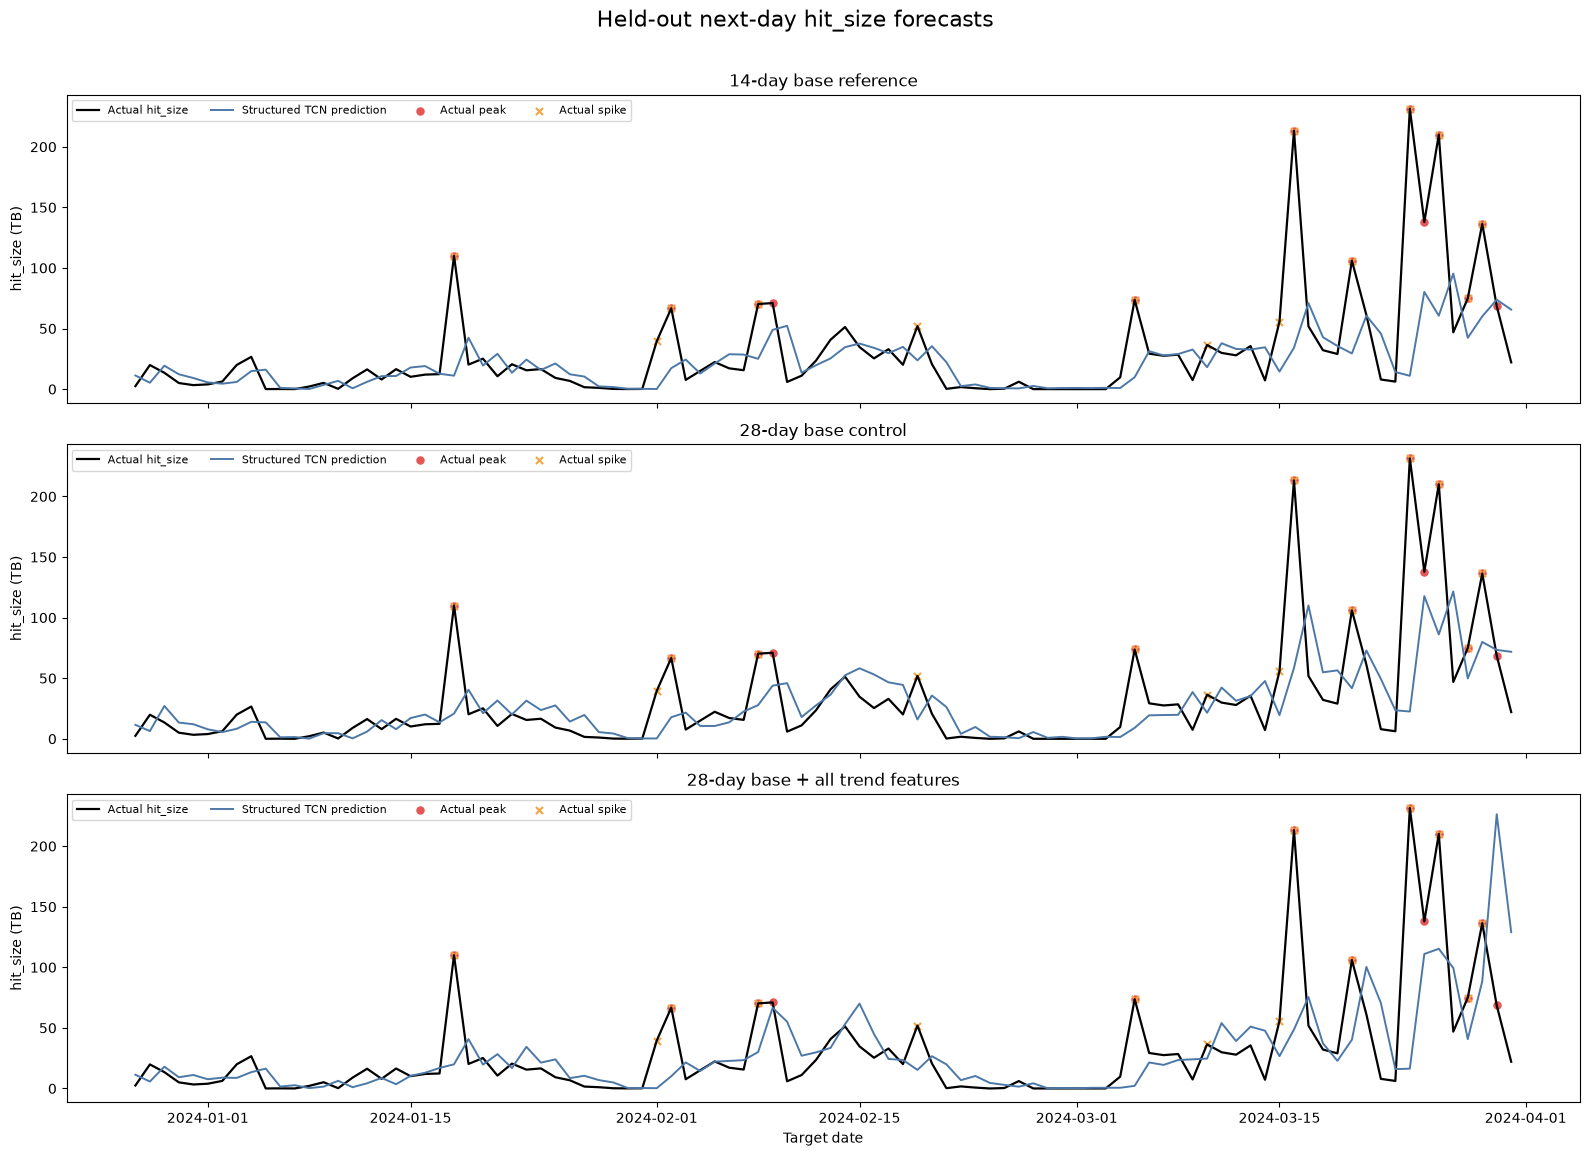

,model,variable,event,threshold,actual event days,predicted event days,precision,recall
0,14-day base reference,hit_count,Peak,26221.800781,14,12,0.417,0.357
1,14-day base reference,hit_count,Spike,9699.599609,16,1,0.000,0.000
2,14-day base reference,hit_size,Peak,61.979000,13,5,0.400,0.154
3,14-day base reference,hit_size,Spike,24.156000,14,0,0.000,0.000
4,28-day base control,hit_count,Peak,26221.800781,14,24,0.375,0.643
5,28-day base control,hit_count,Spike,9699.599609,16,31,0.161,0.312
6,28-day base control,hit_size,Peak,61.979000,13,8,0.500,0.308
7,28-day base control,hit_size,Spike,24.156000,14,1,0.000,0.000
8,28-day base + all trend features,hit_count,Peak,26221.800781,14,10,0.400,0.286
9,28-day base + all trend features,hit_count,Spike,9699.599609,16,5,0.400,0.125


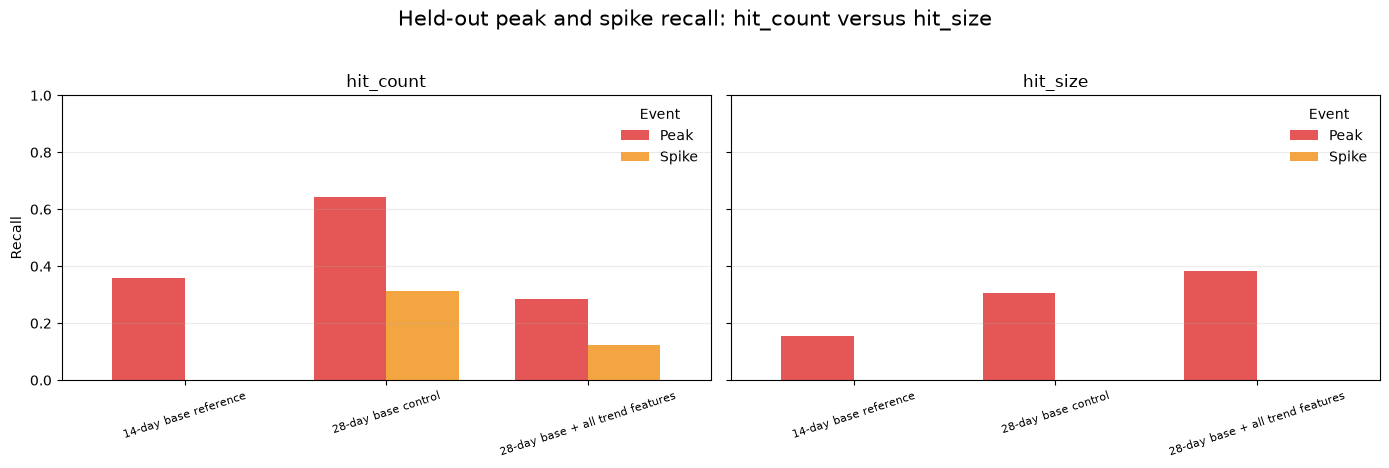

In [22]:
fig, axes = plt.subplots(len(EXPERIMENTS), 1, figsize=(16, 3.8 * len(EXPERIMENTS)), sharex=True)
if len(EXPERIMENTS) == 1:
    axes = [axes]
for axis, config in zip(axes, EXPERIMENTS):
    model_name = config['model']
    plot_df = prediction_tables[model_name]
    axis.plot(plot_df['target_date'], plot_df['hit_size_actual'], color='black', linewidth=1.6, label='Actual hit_size')
    axis.plot(plot_df['target_date'], plot_df['hit_size_predicted'], color='#4c78a8', linewidth=1.4, label='Structured TCN prediction')
    axis.scatter(plot_df.loc[plot_df['is_peak'], 'target_date'], plot_df.loc[plot_df['is_peak'], 'hit_size_actual'], color='#e45756', s=26, label='Actual peak')
    axis.scatter(plot_df.loc[plot_df['is_spike'], 'target_date'], plot_df.loc[plot_df['is_spike'], 'hit_size_actual'], color='#f2a541', s=26, marker='x', label='Actual spike')
    axis.set_title(model_name)
    axis.set_ylabel('hit_size (TB)')
    axis.legend(loc='upper left', ncol=4, fontsize=8)
axes[-1].set_xlabel('Target date')
fig.suptitle('Held-out next-day hit_size forecasts', y=1.01, fontsize=16)
fig.tight_layout()
fig.savefig(output_dir / 'held_out_hit_size_forecasts.png', dpi=200, bbox_inches='tight')
plt.show()

# Reuse the existing forecasts to test whether hit_count has more predictable peak or spike signals.
EVENT_VARIABLES = ['hit_count', 'hit_size']
required_columns = {'hit_count_actual', 'hit_count_predicted', 'hit_count_previous'}
if not required_columns.issubset(next(iter(prediction_tables.values())).columns):
    raise RuntimeError('Re-run Section 3 once to save all six predictions, then re-run this cell. No new model design is required.')

train_positions_for_events = date_to_position.loc[split['train_start']:split['train_end']].to_numpy()
event_rows = []
for config in EXPERIMENTS:
    model_name = config['model']
    table = prediction_tables[model_name]
    for variable in EVENT_VARIABLES:
        variable_index = FEATURE_NAMES.index(variable)
        train_level = raw_values[train_positions_for_events, variable_index]
        train_change = train_level[1:] - train_level[:-1]
        peak_threshold = np.quantile(train_level, PEAK_QUANTILE)
        spike_threshold = np.quantile(train_change, SPIKE_QUANTILE)
        actual_peak = table[f'{variable}_actual'].to_numpy() >= peak_threshold
        predicted_peak = table[f'{variable}_predicted'].to_numpy() >= peak_threshold
        actual_spike = (table[f'{variable}_actual'] - table[f'{variable}_previous']).to_numpy() >= spike_threshold
        predicted_spike = (table[f'{variable}_predicted'] - table[f'{variable}_previous']).to_numpy() >= spike_threshold
        for event_name, observed, forecast, threshold in [
            ('Peak', actual_peak, predicted_peak, peak_threshold),
            ('Spike', actual_spike, predicted_spike, spike_threshold),
        ]:
            precision, recall = event_metrics(observed, forecast)
            event_rows.append({
                'model': model_name, 'variable': variable, 'event': event_name,
                'threshold': threshold, 'actual event days': int(observed.sum()),
                'predicted event days': int(forecast.sum()),
                'precision': precision, 'recall': recall,
            })

hit_event_results = pd.DataFrame(event_rows)
hit_event_results.to_csv(output_dir / 'hit_count_and_hit_size_event_metrics.csv', index=False)
display(hit_event_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for axis, variable in zip(axes, EVENT_VARIABLES):
    rows = hit_event_results[hit_event_results['variable'] == variable]
    recall_table = rows.pivot(index='model', columns='event', values='recall').reindex([config['model'] for config in EXPERIMENTS])
    recall_table.plot.bar(ax=axis, color=['#e45756', '#f2a541'], width=.72)
    axis.set_title(variable)
    axis.set_xlabel('')
    axis.set_ylabel('Recall')
    axis.set_ylim(0, 1)
    axis.tick_params(axis='x', rotation=18, labelsize=8)
    axis.grid(axis='y', alpha=.25)
    axis.legend(title='Event', frameon=False)
fig.suptitle('Held-out peak and spike recall: hit_count versus hit_size', y=1.03, fontsize=15)
fig.tight_layout()
fig.savefig(output_dir / 'hit_count_vs_hit_size_peak_spike_recall.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Regime robustness: five seeds versus persistence

This section compares two fixed models in three separate regimes: the **28-day base Structured TCN** and the **28-day base + all trend features Structured TCN**. The regimes are first (2020-05-31 to 2021-09-30), middle (2021-10-01 to 2022-06-30), and late (2022-07-01 to 2024-03-31). Each regime has its own chronological 70%/15%/15% split and train-only scalers. Input windows and trend calculations are kept completely inside the applicable regime.

Five independent random seeds are trained for each model in each regime. TCN results are reported as median seed-wise test RMSE, not as an ensemble. Persistence is deterministic and uses the previous observed day.

In [23]:
REGIME_LOOKBACK = 28
ROBUSTNESS_SEEDS = [7, 21, 42, 84, 2026]
ROBUSTNESS_MODELS = [
    {'model': '28-day base Structured TCN', 'use_trends': False},
    {'model': '28-day base + all trend features', 'use_trends': True},
]
REGIME_SPLITS = {
    'First in-regime': chronological_split('2020-05-31', '2021-09-30'),
    'Middle in-regime': chronological_split('2021-10-01', '2022-06-30'),
    'Late in-regime': chronological_split('2022-07-01', '2024-03-31'),
}

display(pd.DataFrame([
    {'regime': name, 'subset': subset.title(), 'first target': bounds[f'{subset}_start'].date(), 'last target': bounds[f'{subset}_end'].date(), 'days': len(pd.date_range(bounds[f'{subset}_start'], bounds[f'{subset}_end']))}
    for name, bounds in REGIME_SPLITS.items() for subset in ['train', 'validation', 'test']
]))
print('TCN fits to run:', len(REGIME_SPLITS) * len(ROBUSTNESS_MODELS) * len(ROBUSTNESS_SEEDS))

,regime,subset,first target,last target,days
0,First in-regime,Train,2020-05-31,2021-05-06,341
1,First in-regime,Validation,2021-05-07,2021-07-18,73
2,First in-regime,Test,2021-07-19,2021-09-30,74
3,Middle in-regime,Train,2021-10-01,2022-04-09,191
4,Middle in-regime,Validation,2022-04-10,2022-05-19,40
5,Middle in-regime,Test,2022-05-20,2022-06-30,42
6,Late in-regime,Train,2022-07-01,2023-09-21,448
7,Late in-regime,Validation,2023-09-22,2023-12-26,96
8,Late in-regime,Test,2023-12-27,2024-03-31,96


TCN fits to run: 30


In [24]:
def fit_regime_seed(regime_name, bounds, model_config, seed):
    start_position = int(date_to_position.loc[bounds['train_start']])
    train_raw = date_to_position.loc[bounds['train_start']:bounds['train_end']].to_numpy()
    validation_positions = date_to_position.loc[bounds['validation_start']:bounds['validation_end']].to_numpy()
    test_positions = date_to_position.loc[bounds['test_start']:bounds['test_end']].to_numpy()
    # Trend values at an input day need 28 earlier days; use a common target start for both models.
    train_positions = train_raw[train_raw >= start_position + 2 * REGIME_LOOKBACK]

    base = np.log1p(raw_values).astype(np.float32)
    regime_end_position = int(date_to_position.loc[bounds['test_end']])
    # Recompute trend features after the regime starts so no MA/EMA value crosses a change point.
    local_trend = build_trend_features(df['hit_size'].iloc[start_position:regime_end_position + 1])
    trend_values = np.full((len(df), len(TREND_NAMES)), np.nan, dtype=np.float32)
    trend_values[start_position:regime_end_position + 1] = local_trend.to_numpy(dtype=np.float32)
    all_inputs = np.column_stack([base, trend_values]) if model_config['use_trends'] else base
    scaler_positions = train_raw[train_raw >= start_position + REGIME_LOOKBACK]
    input_scaler = StandardScaler().fit(all_inputs[scaler_positions])
    inputs = input_scaler.transform(all_inputs).astype(np.float32)
    count_ratio = np.divide(raw_values[:, 2], raw_values[:, 0], out=np.zeros(len(df)), where=raw_values[:, 0] > 0)
    size_ratio = np.divide(raw_values[:, 3], raw_values[:, 1], out=np.zeros(len(df)), where=raw_values[:, 1] > 0)
    log_access = np.column_stack([np.log1p(raw_values[:, 0]), np.log1p(raw_values[:, 1])]).astype(np.float32)
    access_scaler = StandardScaler().fit(log_access[train_raw])
    labels = np.column_stack([access_scaler.transform(log_access), count_ratio, size_ratio]).astype(np.float32)

    def sequences(positions):
        return np.asarray([inputs[p - REGIME_LOOKBACK:p] for p in positions], dtype=np.float32)

    x_train, y_train = sequences(train_positions), labels[train_positions]
    x_validation, y_validation = sequences(validation_positions), labels[validation_positions]
    x_test = sequences(test_positions)

    def decode(model, features):
        model.eval(); rows = []
        with torch.no_grad():
            for left in range(0, len(features), BATCH_SIZE):
                batch = torch.tensor(features[left:left + BATCH_SIZE].transpose(0, 2, 1), dtype=torch.float32, device=device)
                rows.extend(model(batch).cpu().tolist())
        output = np.asarray(rows, dtype=np.float64)
        access = np.maximum(np.expm1(access_scaler.inverse_transform(output[:, :2])), 0)
        ratio = np.clip(output[:, 2:], 0, 1)
        return np.column_stack([access[:, 0], access[:, 1], access[:, 0] * ratio[:, 0], access[:, 1] * ratio[:, 1], access[:, 0] * (1 - ratio[:, 0]), access[:, 1] * (1 - ratio[:, 1])])

    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    model = StructuredTCN(input_channels=inputs.shape[1]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loader = make_loader(x_train, y_train, shuffle=True)
    validation_actual = raw_values[validation_positions]
    best_rmse, best_state, best_epoch, stale = float('inf'), None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad(); loss = structured_loss(model(xb.to(device)), yb.to(device)); loss.backward(); optimizer.step()
        validation_prediction = decode(model, x_validation)
        validation_rmse = float(np.sqrt(np.mean((validation_prediction[:, PRIMARY_INDEX] - validation_actual[:, PRIMARY_INDEX]) ** 2)))
        if validation_rmse < best_rmse:
            best_rmse, best_state, best_epoch, stale = validation_rmse, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            stale += 1
        if stale >= PATIENCE: break
    model.load_state_dict(best_state)

    prediction, actual, persistence = decode(model, x_test), raw_values[test_positions], raw_values[test_positions - 1]
    result = {'regime': regime_name, 'model': model_config['model'], 'use_trends': model_config['use_trends'], 'seed': seed, 'lookback': REGIME_LOOKBACK, 'input_channels': inputs.shape[1], 'best_epoch': best_epoch, 'validation_hit_size_rmse': best_rmse, 'test_days': len(test_positions)}
    for index, variable in enumerate(FEATURE_NAMES):
        result[f'tcn_{variable}_rmse'] = float(np.sqrt(np.mean((prediction[:, index] - actual[:, index]) ** 2)))
        result[f'persistence_{variable}_rmse'] = float(np.sqrt(np.mean((persistence[:, index] - actual[:, index]) ** 2)))

    delta_train = train_raw[1:]
    peak_threshold = np.quantile(raw_values[train_raw, PRIMARY_INDEX], PEAK_QUANTILE)
    spike_threshold = np.quantile(raw_values[delta_train, PRIMARY_INDEX] - raw_values[delta_train - 1, PRIMARY_INDEX], SPIKE_QUANTILE)
    actual_peak = actual[:, PRIMARY_INDEX] >= peak_threshold
    predicted_peak = prediction[:, PRIMARY_INDEX] >= peak_threshold
    actual_spike = actual[:, PRIMARY_INDEX] - persistence[:, PRIMARY_INDEX] >= spike_threshold
    predicted_spike = prediction[:, PRIMARY_INDEX] - persistence[:, PRIMARY_INDEX] >= spike_threshold
    persistence_peak = persistence[:, PRIMARY_INDEX] >= peak_threshold
    persistence_spike = np.zeros(len(test_positions), dtype=bool)
    for name, observed, forecast, persistence_forecast in [('peak', actual_peak, predicted_peak, persistence_peak), ('spike', actual_spike, predicted_spike, persistence_spike)]:
        event_error = prediction[observed, PRIMARY_INDEX] - actual[observed, PRIMARY_INDEX]
        precision, recall = event_metrics(observed, forecast)
        result[f'{name}_days'] = int(observed.sum())
        result[f'tcn_{name}_rmse'] = float(np.sqrt(np.mean(event_error ** 2))) if len(event_error) else np.nan
        result[f'tcn_{name}_bias'] = float(np.mean(event_error)) if len(event_error) else np.nan
        _, persistence_recall = event_metrics(observed, persistence_forecast)
        result[f'tcn_{name}_precision'], result[f'tcn_{name}_recall'] = precision, recall
        result[f'persistence_{name}_recall'] = persistence_recall
    return result

regime_seed_rows = []
for regime_name, bounds in REGIME_SPLITS.items():
    for model_config in ROBUSTNESS_MODELS:
        for seed in ROBUSTNESS_SEEDS:
            print(f"Running {regime_name}: {model_config['model']}, seed={seed}")
            regime_seed_rows.append(fit_regime_seed(regime_name, bounds, model_config, seed))
regime_seed_results = pd.DataFrame(regime_seed_rows)
display(regime_seed_results.sort_values(['regime', 'seed']))

Running First in-regime: 28-day base Structured TCN, seed=7
Running First in-regime: 28-day base Structured TCN, seed=21
Running First in-regime: 28-day base Structured TCN, seed=42
Running First in-regime: 28-day base Structured TCN, seed=84
Running First in-regime: 28-day base Structured TCN, seed=2026
Running First in-regime: 28-day base + all trend features, seed=7
Running First in-regime: 28-day base + all trend features, seed=21
Running First in-regime: 28-day base + all trend features, seed=42
Running First in-regime: 28-day base + all trend features, seed=84
Running First in-regime: 28-day base + all trend features, seed=2026
Running Middle in-regime: 28-day base Structured TCN, seed=7
Running Middle in-regime: 28-day base Structured TCN, seed=21
Running Middle in-regime: 28-day base Structured TCN, seed=42
Running Middle in-regime: 28-day base Structured TCN, seed=84
Running Middle in-regime: 28-day base Structured TCN, seed=2026
Running Middle in-regime: 28-day base + all tre

,regime,model,use_trends,seed,lookback,input_channels,best_epoch,validation_hit_size_rmse,test_days,tcn_access_count_rmse,...,tcn_peak_bias,tcn_peak_precision,tcn_peak_recall,persistence_peak_recall,spike_days,tcn_spike_rmse,tcn_spike_bias,tcn_spike_precision,tcn_spike_recall,persistence_spike_recall
0,First in-regime,28-day base Structured TCN,False,7,28,6,2,4.675201,74,22661.270044,...,-22.790075,0.000000,0.000000,0.000000,7,22.652146,-20.131516,0.000000,0.000000,0.0
5,First in-regime,28-day base + all trend features,True,7,28,18,4,4.714071,74,21553.590343,...,-22.669953,0.000000,0.000000,0.000000,7,23.380621,-20.797954,0.000000,0.000000,0.0
1,First in-regime,28-day base Structured TCN,False,21,28,6,4,4.697877,74,22089.954425,...,-22.819941,0.000000,0.000000,0.000000,7,23.087707,-20.460711,0.000000,0.000000,0.0
6,First in-regime,28-day base + all trend features,True,21,28,18,7,4.626706,74,25345.420388,...,-21.959941,0.000000,0.000000,0.000000,7,23.124737,-20.436517,0.000000,0.000000,0.0
2,First in-regime,28-day base Structured TCN,False,42,28,6,3,4.596175,74,19547.546116,...,-21.189087,0.000000,0.000000,0.000000,7,22.213710,-19.656083,0.000000,0.000000,0.0
7,First in-regime,28-day base + all trend features,True,42,28,18,7,4.628161,74,22980.251705,...,-20.941820,0.333333,0.166667,0.000000,7,24.186002,-21.388955,0.000000,0.000000,0.0
3,First in-regime,28-day base Structured TCN,False,84,28,6,5,4.761229,74,22928.061113,...,-22.730895,0.000000,0.000000,0.000000,7,22.809268,-20.524766,0.000000,0.000000,0.0
8,First in-regime,28-day base + all trend features,True,84,28,18,4,4.654811,74,21527.027229,...,-23.157206,0.000000,0.000000,0.000000,7,23.820215,-21.164386,0.000000,0.000000,0.0
4,First in-regime,28-day base Structured TCN,False,2026,28,6,5,4.727761,74,21723.214748,...,-20.922947,0.000000,0.000000,0.000000,7,21.171345,-18.543979,0.000000,0.000000,0.0
9,First in-regime,28-day base + all trend features,True,2026,28,18,7,4.912344,74,22023.631939,...,-21.672023,0.000000,0.000000,0.000000,7,22.539228,-19.992755,0.000000,0.000000,0.0


,regime,model,variable,TCN median RMSE,TCN IQR,TCN min RMSE,TCN max RMSE,Persistence RMSE,median improvement vs persistence (%)
1,First in-regime,28-day base Structured TCN,access_size,13.471,0.083,13.243,13.700,15.547,13.353
3,First in-regime,28-day base Structured TCN,hit_size,8.805,0.129,8.672,8.906,9.893,10.992
7,First in-regime,28-day base + all trend features,access_size,14.223,0.274,13.990,14.515,15.547,8.519
9,First in-regime,28-day base + all trend features,hit_size,9.435,0.402,9.039,10.157,9.893,4.626
13,Middle in-regime,28-day base Structured TCN,access_size,21.113,0.531,19.394,27.617,18.244,-15.723
15,Middle in-regime,28-day base Structured TCN,hit_size,6.853,0.479,6.397,7.391,6.068,-12.934
19,Middle in-regime,28-day base + all trend features,access_size,26.753,5.287,21.111,32.318,18.244,-46.639
21,Middle in-regime,28-day base + all trend features,hit_size,8.544,0.807,7.241,9.538,6.068,-40.813
25,Late in-regime,28-day base Structured TCN,access_size,39.917,0.544,39.138,40.504,47.845,16.569
27,Late in-regime,28-day base Structured TCN,hit_size,39.394,0.230,38.621,40.000,47.000,16.184


,regime,model,seed,best_epoch,validation_hit_size_rmse,tcn_hit_size_rmse,persistence_hit_size_rmse,tcn_peak_recall,tcn_spike_recall
5,First in-regime,28-day base + all trend features,7,4,4.714,9.251,9.893,0.000,0.000
6,First in-regime,28-day base + all trend features,21,7,4.627,10.157,9.893,0.000,0.000
7,First in-regime,28-day base + all trend features,42,7,4.628,9.653,9.893,0.167,0.000
8,First in-regime,28-day base + all trend features,84,4,4.655,9.039,9.893,0.000,0.000
9,First in-regime,28-day base + all trend features,2026,7,4.912,9.435,9.893,0.000,0.000
0,First in-regime,28-day base Structured TCN,7,2,4.675,8.768,9.893,0.000,0.000
1,First in-regime,28-day base Structured TCN,21,4,4.698,8.906,9.893,0.000,0.000
2,First in-regime,28-day base Structured TCN,42,3,4.596,8.805,9.893,0.000,0.000
3,First in-regime,28-day base Structured TCN,84,5,4.761,8.896,9.893,0.000,0.000
4,First in-regime,28-day base Structured TCN,2026,5,4.728,8.672,9.893,0.000,0.000


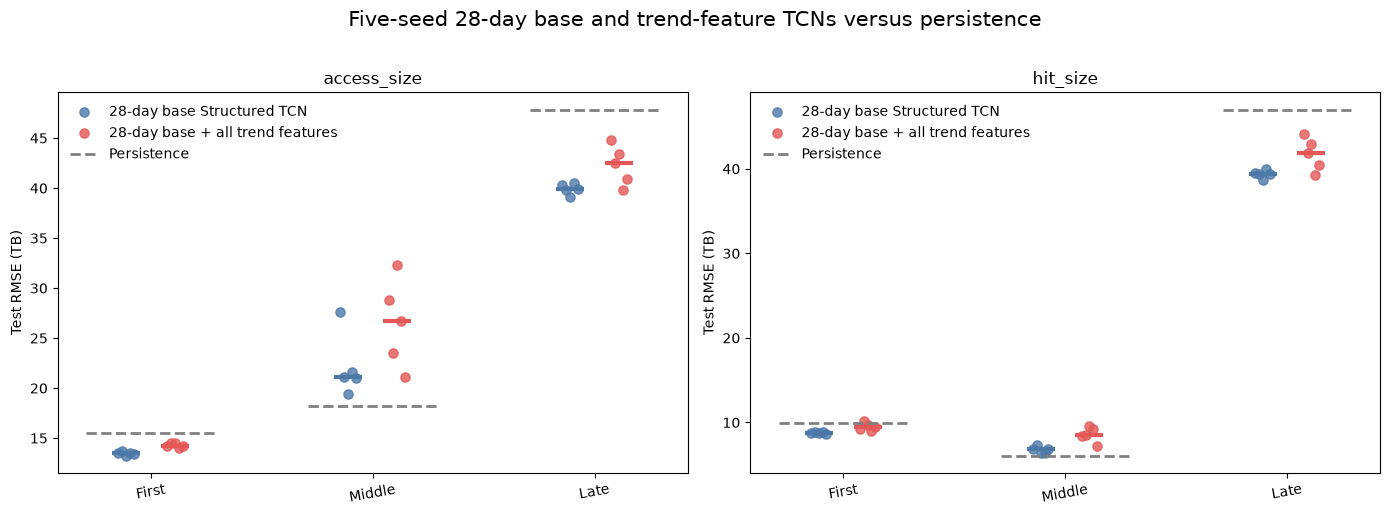

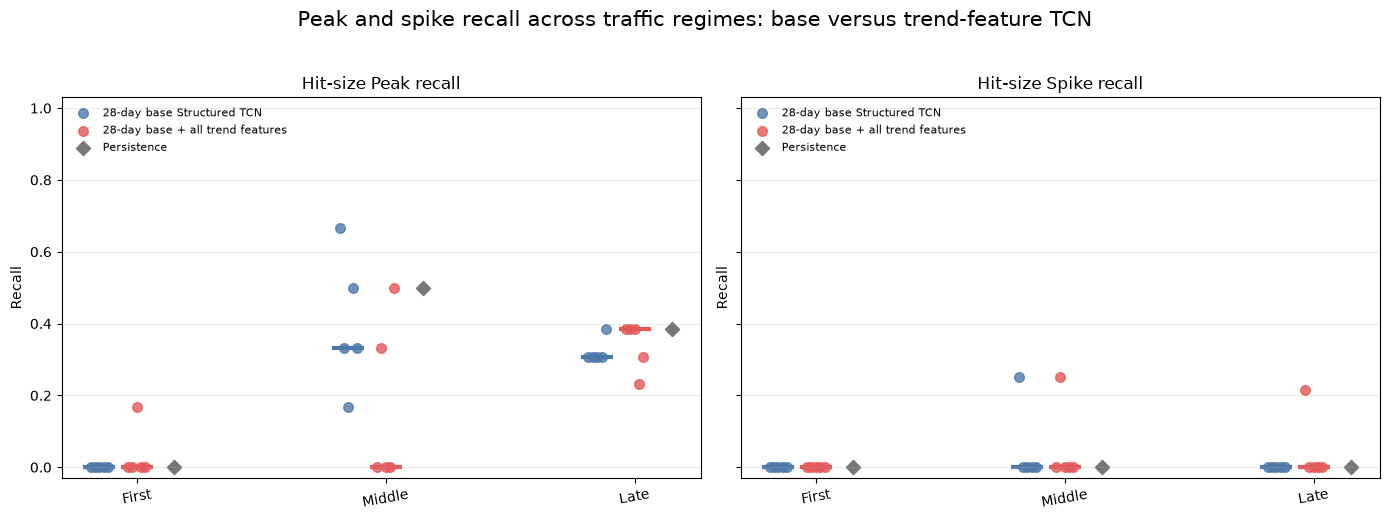

Saved results to: /Users/dengyingxin/Desktop/xcache/week7/results/regime_seed_robustness


In [25]:
week7_dir = Path.cwd() if (Path.cwd() / 'Sammy_TCN_261021.ipynb').exists() else Path.cwd() / 'week7'
robustness_dir = week7_dir / 'results' / 'regime_seed_robustness'
robustness_dir.mkdir(parents=True, exist_ok=True)
regime_seed_results.to_csv(robustness_dir / 'seedwise_regime_results.csv', index=False)

summary_rows = []
for (regime_name, model_name), rows in regime_seed_results.groupby(['regime', 'model'], sort=False):
    for variable in FEATURE_NAMES:
        values = rows[f'tcn_{variable}_rmse']
        baseline = rows[f'persistence_{variable}_rmse'].iloc[0]
        summary_rows.append({'regime': regime_name, 'model': model_name, 'variable': variable, 'TCN median RMSE': values.median(), 'TCN IQR': values.quantile(.75) - values.quantile(.25), 'TCN min RMSE': values.min(), 'TCN max RMSE': values.max(), 'Persistence RMSE': baseline, 'median improvement vs persistence (%)': 100 * (baseline - values.median()) / baseline})
regime_summary = pd.DataFrame(summary_rows)
regime_summary.to_csv(robustness_dir / 'median_tcn_vs_persistence_by_regime.csv', index=False)
display(regime_summary[regime_summary['variable'].isin(['access_size', 'hit_size'])].round(3))
display(regime_seed_results[['regime', 'model', 'seed', 'best_epoch', 'validation_hit_size_rmse', 'tcn_hit_size_rmse', 'persistence_hit_size_rmse', 'tcn_peak_recall', 'tcn_spike_recall']].sort_values(['regime', 'model', 'seed']).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, variable in zip(axes, ['access_size', 'hit_size']):
    for x, regime_name in enumerate(REGIME_SPLITS):
        regime_rows = regime_seed_results[regime_seed_results['regime'] == regime_name]
        for model_index, model_config in enumerate(ROBUSTNESS_MODELS):
            rows = regime_rows[regime_rows['model'] == model_config['model']]
            values = rows[f'tcn_{variable}_rmse'].to_numpy()
            center = x + (-0.11 if model_index == 0 else 0.11)
            color = '#4c78a8' if model_index == 0 else '#e45756'
            axis.scatter(center + np.linspace(-.035, .035, len(values)), values, color=color, s=44, alpha=.8, label=model_config['model'] if x == 0 else None)
            axis.scatter(center, np.median(values), color=color, marker='_', s=430, linewidths=3)
        axis.hlines(regime_rows[f'persistence_{variable}_rmse'].iloc[0], x - .29, x + .29, color='gray', linestyle='--', linewidth=2, label='Persistence' if x == 0 else None)
    axis.set_xticks(range(len(REGIME_SPLITS)), [name.replace(' in-regime', '') for name in REGIME_SPLITS], rotation=10)
    axis.set_ylabel('Test RMSE (TB)'); axis.set_title(variable); axis.legend(frameon=False)
fig.suptitle('Five-seed 28-day base and trend-feature TCNs versus persistence', y=1.02, fontsize=15)
fig.tight_layout()
fig.savefig(robustness_dir / 'five_seed_tcn_vs_persistence_by_regime.png', dpi=200, bbox_inches='tight')
plt.show()

# Compare event detection directly: each dot is one seed and the horizontal marker is the median.
event_labels = [('peak', 'Peak recall'), ('spike', 'Spike recall')]
model_colors = ['#4c78a8', '#e45756']
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for axis, (event_name, event_title) in zip(axes, event_labels):
    for x, regime_name in enumerate(REGIME_SPLITS):
        regime_rows = regime_seed_results[regime_seed_results['regime'] == regime_name]
        for model_index, model_config in enumerate(ROBUSTNESS_MODELS):
            rows = regime_rows[regime_rows['model'] == model_config['model']]
            values = rows[f'tcn_{event_name}_recall'].to_numpy()
            center = x + (-0.15 if model_index == 0 else 0.0)
            axis.scatter(center + np.linspace(-.035, .035, len(values)), values, color=model_colors[model_index], s=48, alpha=.8, label=model_config['model'] if x == 0 else None)
            axis.scatter(center, np.median(values), color=model_colors[model_index], marker='_', s=500, linewidths=3)
        persistence_column = f'persistence_{event_name}_recall'
        if persistence_column in regime_rows.columns:
            persistence_value = regime_rows[persistence_column].iloc[0]
            axis.scatter(x + .15, persistence_value, color='#777777', marker='D', s=52, label='Persistence' if x == 0 else None)
    axis.set_xticks(range(len(REGIME_SPLITS)), [name.replace(' in-regime', '') for name in REGIME_SPLITS], rotation=10)
    axis.set_ylim(-.03, 1.03)
    axis.set_ylabel('Recall')
    axis.set_title(f'Hit-size {event_title}')
    axis.grid(axis='y', alpha=.25)
    axis.legend(frameon=False, fontsize=8, loc='upper left')
fig.suptitle('Peak and spike recall across traffic regimes: base versus trend-feature TCN', y=1.03, fontsize=15)
fig.tight_layout()
fig.savefig(robustness_dir / 'peak_and_spike_recall_by_regime_and_model.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved results to:', robustness_dir.resolve())